## Klasifikacija recenzija mobilnih aplikacija pomocu biblioteka **spaCy** i sklearn (Bag of Words i Decision Trees)

Zadatak klasifikacije u ovom notebook-u je razvrstavanje recenzija korisnika mobilnih aplikacija u tri kategorije, koriscenjem **Bag of Words (BoW)** pristupa za predstavljanje teksta i algoritma stabla odlučivanja (Decision Tree – DT) za klasifikaciju:
* funkcionalni zahtevi,
* nefunkcionalni zahtevi,
* ostalo.

Skup podataka korišćen u ovom notebooku potiče iz  [Listening to the Crowd for the Release Planning of Mobile Apps](https://dl.acm.org/doi/abs/10.1109/TSE.2017.2759112).

In [1]:
# UCITAVANJE POTREBNIH BIBLIOTEKA

import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import metrics

from sklearn.tree import DecisionTreeClassifier

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import matplotlib.pyplot as plt
import seaborn as sb

import spacy

from IPython.display import display

from pathlib import Path

import pickle
import json

In [2]:
RAND_STATE = 1

#### UCITAVANJE PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'mobile_apps_reviews.csv')

display(data.head(10))
data.info()

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER
5,6,com.androtiyas.dragonvirtual,1.11,5,1391710690867,?,Aribha Zahoor,hope this is a good game!!!! ?,OTHER
6,7,com.androtiyas.dragonvirtual,?,1,1396716326980,LG Optimus One,isaiah lawrence,sucks can't even play offline and everyone tak...,FEATURE
7,8,com.androtiyas.dragonvirtual,1.12,5,1397085800819,Samsung Galaxy Y,Charlotte Baynes,good that is so good,OTHER
8,9,com.androtiyas.dragonvirtual,1.1,5,1389305213694,HTC Wildfire S,A Google User,? realy good and fun,OTHER
9,10,com.androtiyas.dragonvirtual,1.11,5,1391957108087,?,Jennifer Bieber,999 this is the best,OTHER


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        3000 non-null   int64 
 1   app       3000 non-null   object
 2   version   3000 non-null   object
 3   rating    3000 non-null   int64 
 4   date      3000 non-null   int64 
 5   device    3000 non-null   object
 6   user      2991 non-null   object
 7   review    3000 non-null   object
 8   category  3000 non-null   object
dtypes: int64(3), object(6)
memory usage: 211.1+ KB


#### KREIRANJE IZLAZNE VARIJABLE

Koristicemo kolonu **_category_** za kreiranje izlazne varijable **_cls_**.

In [4]:
# pravimo novu kolonu cls sa 3 moguce vrednosti: OTHER, FUNCTIONAL (BUG, FEATURE) i NON-FUNCTIONAL (PERFORMANCE, USABILITY, ENERGY, SECURITY)

def category_to_cls(cat):
    if cat == 'OTHER': return cat
    return 'FUNCTIONAL' if cat in ['BUG', 'FEATURE'] else 'NON-FUNCTIONAL'


data['cls'] = data.category.apply(category_to_cls)

Provera balansiranosti dataseta

In [5]:
data.cls.value_counts(normalize=True)

# postoji class imbalance - klase nisu podjednako zastupljenje
# model moze da vara

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

Ako algoritam uopste ne analizira tekst recenzije, vec za svaku mogucu recenziju kaze da pripada klasi OTHER, on ce automatski imati tacnost (accuracy) od 50%.

Kreiranje varijable _review_len__

In [6]:
# duzina recenzija moze biti bitna - npr. duzi tekst uglavnom znaci da je u pitanju bag

data['review_len'] = data.review.apply(len)

In [8]:
# trenutni izgled dataseta:

data.head()

,id,app,version,rating,date,device,user,review,category,cls,review_len
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER,OTHER,40
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER,OTHER,41
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER,OTHER,60
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG,FUNCTIONAL,295
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER,OTHER,43


#### Provera znacajnosti prediktora

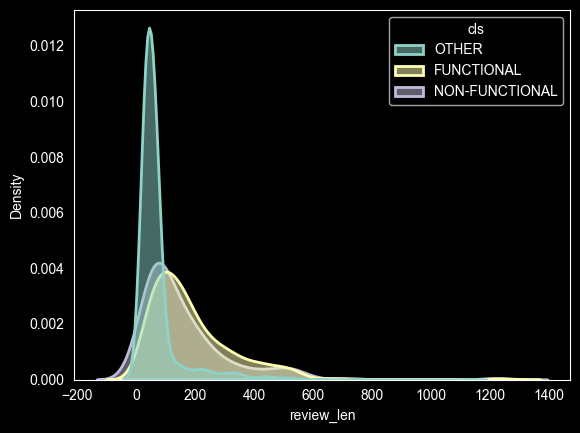

In [9]:
# review_len

plt.figure()
sb.kdeplot(data=data,
           x='review_len',
           hue='cls',
           fill=True,
           common_norm=False,
           # svaka kriva se normalizuje zasebno (povrsina = 1), pa se mogu porediti oblici raspodela bez obzira na to koliko je klasa velika
           alpha=0.5,
           linewidth=2)
plt.grid(False) # ja dodala jer je kod mene automatski grid
plt.show()

# izdvaja bar jednu klasu od ostale dve -> znacajan prediktor

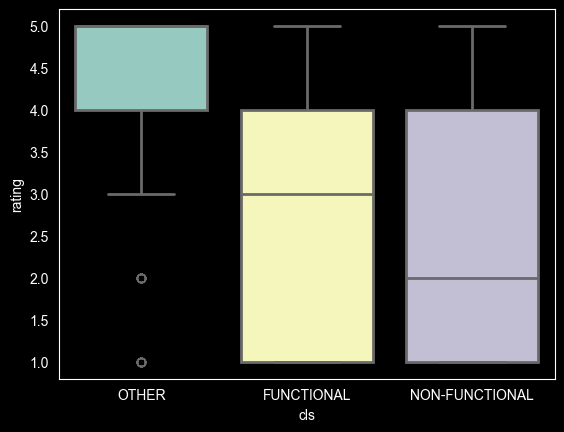

In [10]:
# rating

plt.figure()
# moze i ovde kdeplot
sb.boxplot(data=data,
           x='cls',
           y='rating',
           hue='cls', # kolona koja se koristi za bojenje - svaka ima svoju boju
           fill=True,
           linewidth=2,
           legend=False)
plt.grid(False)
plt.show()

# medijane po klasama se razlikuju (4,3,2) -> rating je takodje znacajan prediktor

In [11]:
# zadrzavamo tri prediktora (rating, review_len, review) i izlaznu varijablu (cls)

data_sub = data[['rating', 'review_len', 'review', 'cls']]

data_sub.head()

,rating,review_len,review,cls
0,5,40,cute!!!! the game is just to cute!!!! :3,OTHER
1,4,41,? well its ok but not bad nor is it great,OTHER
2,1,60,? have no idea how to feed dragon and boooorrr...,OTHER
3,2,295,when i play games it reboots about every third...,FUNCTIONAL
4,5,43,love my dragon have fun! yahoooey! godbless,OTHER


## PRETPROCESIRANJE TEKSTA (spacy)

In [12]:
# ucitavanje pipeline-a
nlp_pipe = spacy.load('en_core_web_sm')

In [13]:
def spacy_preprocessing(doc):
    # kreiranje tokena sa lingvistickim osobinama
    tokens = nlp_pipe(doc)
    # uklanjanje interpunkcija, praznina, brojeva i url
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and
                  (not token.like_num) and (not token.like_url))]
    # uklanjanje stop words, ali ostavljamo not - kljucno za analizu sentimenta (good != not good)
    tokens = [token for token in tokens
              if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]

    # pretvaranje tokena u leme
    words = [token.lemma_ for token in tokens]

    # vracanje pretprocesuiranih reci
    return words

In [14]:
def create_count_vectorizer(ngrams=(1, 1), min_doc_freq=0.01, f_max=-1):
    vectoriser = CountVectorizer(
        tokenizer=spacy_preprocessing,  #umesto ugradjenog deljenja teksta, koristimo svoju funkciju
        token_pattern=None,  #kazemo da ne koristi regex
        ngram_range=ngrams,
        max_features=f_max if f_max > 0 else None,  # ogranicava recnik na n najcescih reci
        min_df=min_doc_freq  # rec ulazi u recnik samo ako se pojavljuje u najmanje 1% dokumenta
    )

    return vectoriser

# ngram_range=(1,1): n-gram je niz od n uzastopnih reci; (1,1) znaci samo pojedinacne reci (unigrami); (1,2) bi dodalo i parove ("not work"), cime se delimicno vraca kontekst, ali se recnik jako povecava

# max_features: ako je prosledjeni f_max veci od 0, zadrzace se samo top f_max najucestalijih reci
# posto je podrazumevano -1, uslov f_max > 0 nije ispunjen, pa se uzima None (recnik se ne ogranicava)

### Kreiranje i testiranje **pipeline**-a za klasifikaciju teksta

#### DELJENJE PODATAKA NA TRAIN I TEST SKUP

In [15]:
X = data_sub.drop(columns='cls')
y = data_sub.cls.values

In [16]:
# faktorizacija izlazne promenljive na 0 1 2 (Decision Tree moze da radi i sa tekstualnim klasama, ali se ovde klase kodiraju u numericki oblik radi lakseg rada

y_encodings, y_levels = pd.factorize(y) # kodiranje tekstualnih ili kategorickih podataka u numericke vrednosti (celobrojne nizove)

# y_encodings - stvarne numericke oznake klasa: [0, 1, 2, 0, 2]
# y_levels - informacije o tome koji broj predstavlja koju originalnu klasu: ['other','functional', 'non-functional']

display(y_levels)
pd.Series(y_encodings).value_counts()

array(['OTHER', 'FUNCTIONAL', 'NON-FUNCTIONAL'], dtype=object)

0    1505
1    1097
2     398
Name: count, dtype: int64

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y_encodings, # brojevi!!!
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings
                                                    )

#### KREIRANJE VECTORISER-A I COLUMN TRANSFORMER-A

In [18]:
# pravimo instancu count vectoriser-a, koju smo gore definisali
count_vectorizer = create_count_vectorizer()

column_transformer = ColumnTransformer(
    [('word_counts', count_vectorizer, 'review')],
    remainder='passthrough' # sve preostale kolone, nenavedene
)

# [('ime_transformacije', transformator, 'kolona')]
# passthrough - sve kolone koje nismo posebno naveli samo prosledi dalje bez promene

#### KREIRANJE KLASIFIKATORA

In [19]:
# za klasifikaciju koristimo decision tree

classifier = DecisionTreeClassifier(random_state=RAND_STATE, min_impurity_decrease=0.001)

# min_impurity_decrease - kontrola grananja stabla

#### DEFINISANJE I TRENING PIPELINE-A